# Practical Application III: Comparing Classifiers

## Bank Term-Deposit Marketing

This notebook compares **K-Nearest Neighbors, Logistic Regression, Decision Trees, and Support Vector Machines** for predicting whether a bank client will subscribe to a term deposit. The work follows the CRISP-DM sequence: business understanding, data understanding, preparation, modeling, evaluation, and recommendations.

### Executive summary

- Only **11.27%** of records are successful subscriptions, so accuracy alone is not sufficient.
- `duration` is excluded because call length is unknown before a call and would leak post-contact information into a targeting model.
- Logistic Regression provides the strongest test ROC-AUC (about **0.802**) and is the most interpretable model.
- At the default 0.50 threshold it misses many subscribers. Lowering the threshold to about **0.216** raises recall from roughly **21% to 55%**, while targeting only about **14%** of the test population.
- A class-balanced SVM finds more subscribers (about **63% recall**) but generates more false positives. The preferred deployment choice depends on call-center capacity and the relative cost of missed subscriptions versus unnecessary calls.

## Setup

In [1]:
import time
import warnings

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from scipy.stats import chi2_contingency, mannwhitneyu
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    ConfusionMatrixDisplay,
    accuracy_score,
    confusion_matrix,
    f1_score,
    precision_recall_curve,
    precision_score,
    recall_score,
    roc_auc_score,
)
from sklearn.model_selection import GridSearchCV, StratifiedKFold, cross_val_score, train_test_split
from sklearn.neighbors import KNeighborsClassifier
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.svm import SVC
from sklearn.tree import DecisionTreeClassifier

warnings.filterwarnings("ignore", message="Found unknown categories")
sns.set_theme(style="whitegrid", context="notebook")
pd.set_option("display.max_columns", 30)

RANDOM_STATE = 42

2026-10-21 12:25:43.193 system_profiler[54091:10960872] XType: Using static font registry.


Matplotlib is building the font cache; this may take a moment.


## Problem 1: Understanding the Data

The accompanying paper's *Materials and Methods* section states that the complete collection represents **17 direct-marketing campaigns**, conducted from May 2008 through November 2010. The campaigns originally contained 79,354 contacts. This notebook uses the assignment's `bank-additional-full.csv` modeling dataset.

## Problem 2: Read in the Data

In [2]:
data_path = "data/bank-additional-full.csv"
bank = pd.read_csv(data_path, sep=";")
print(f"Rows: {bank.shape[0]:,}; columns: {bank.shape[1]}")
bank.head()

Rows: 41,188; columns: 21


,age,job,marital,education,default,housing,loan,contact,month,day_of_week,duration,campaign,pdays,previous,poutcome,emp.var.rate,cons.price.idx,cons.conf.idx,euribor3m,nr.employed,y
0,56,housemaid,married,basic.4y,no,no,no,telephone,may,mon,261,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no
1,57,services,married,high.school,unknown,no,no,telephone,may,mon,149,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no
2,37,services,married,high.school,no,yes,no,telephone,may,mon,226,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no
3,40,admin.,married,basic.6y,no,no,no,telephone,may,mon,151,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no
4,56,services,married,high.school,no,no,yes,telephone,may,mon,307,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no


## Problem 3: Understanding the Features

The dataset contains 20 input variables and the binary target `y`. The audit checks data types, literal missing values, duplicate rows, and categorical values labeled `unknown`. The `unknown` values are retained as an explicit category because they may carry information and are not equivalent to a pandas null value.

In [3]:
unknown_counts = {
    column: int((bank[column] == "unknown").sum())
    for column in bank.select_dtypes(include="object").columns
    if (bank[column] == "unknown").any()
}

audit = pd.Series(
    {
        "rows": bank.shape[0],
        "columns": bank.shape[1],
        "duplicate_rows": bank.duplicated().sum(),
        "literal_missing_cells": bank.isna().sum().sum(),
        "unknown_categorical_cells": sum(unknown_counts.values()),
    },
    name="value",
)
display(audit.to_frame())
display(pd.Series(unknown_counts, name="unknown_count").sort_values(ascending=False).to_frame())
display(bank.dtypes.rename("dtype").to_frame())

,value
rows,41188
columns,21
duplicate_rows,12
literal_missing_cells,0
unknown_categorical_cells,12718


,unknown_count
default,8597
education,1731
housing,990
loan,990
job,330
marital,80


,dtype
age,int64
job,object
marital,object
education,object
default,object
housing,object
loan,object
contact,object
month,object
day_of_week,object


In [4]:
bank = bank.drop_duplicates().reset_index(drop=True)
bank["subscribed"] = bank["y"].eq("yes").astype(int)

target_summary = bank["y"].value_counts().rename_axis("outcome").to_frame("count")
target_summary["percent"] = (100 * target_summary["count"] / len(bank)).round(2)
target_summary

,count,percent
outcome,,
no,36537,88.73
yes,4639,11.27


### Descriptive statistics and visualizations

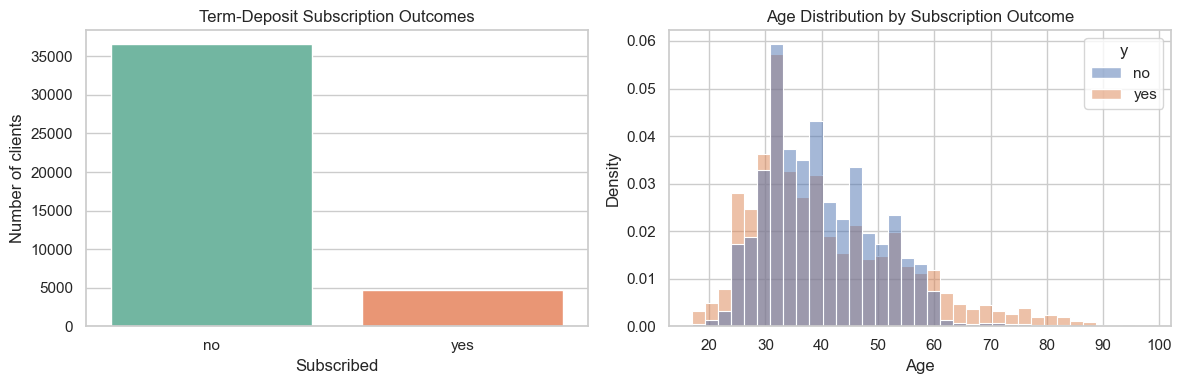

In [5]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
sns.countplot(data=bank, x="y", hue="y", legend=False, ax=axes[0], palette="Set2")
axes[0].set(title="Term-Deposit Subscription Outcomes", xlabel="Subscribed", ylabel="Number of clients")

sns.histplot(data=bank, x="age", hue="y", bins=35, stat="density", common_norm=False, ax=axes[1])
axes[1].set(title="Age Distribution by Subscription Outcome", xlabel="Age", ylabel="Density")
plt.tight_layout()
plt.show()

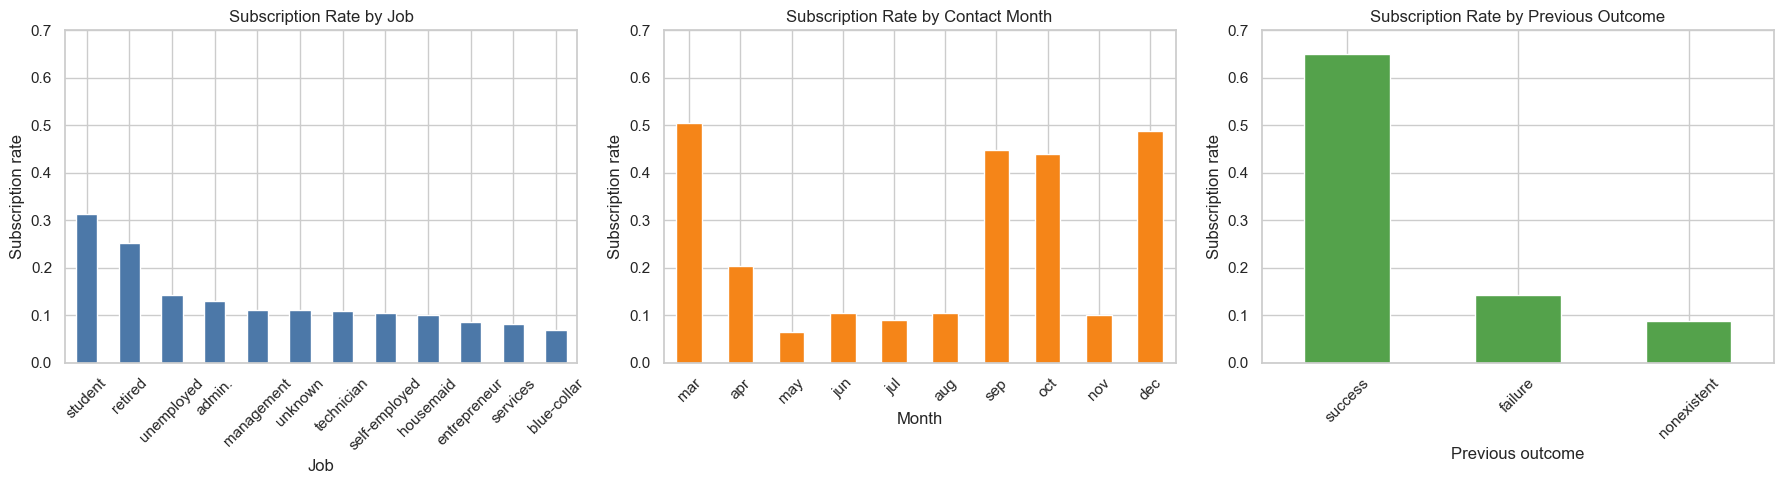

In [6]:
job_rates = bank.groupby("job", observed=True)["subscribed"].mean().sort_values(ascending=False)
month_order = ["mar", "apr", "may", "jun", "jul", "aug", "sep", "oct", "nov", "dec"]
month_rates = bank.groupby("month", observed=True)["subscribed"].mean().reindex(month_order)
poutcome_rates = bank.groupby("poutcome", observed=True)["subscribed"].mean().sort_values(ascending=False)

fig, axes = plt.subplots(1, 3, figsize=(18, 5))
job_rates.plot(kind="bar", ax=axes[0], color="#4C78A8")
month_rates.plot(kind="bar", ax=axes[1], color="#F58518")
poutcome_rates.plot(kind="bar", ax=axes[2], color="#54A24B")

axes[0].set(title="Subscription Rate by Job", xlabel="Job", ylabel="Subscription rate")
axes[1].set(title="Subscription Rate by Contact Month", xlabel="Month", ylabel="Subscription rate")
axes[2].set(title="Subscription Rate by Previous Outcome", xlabel="Previous outcome", ylabel="Subscription rate")
for axis in axes:
    axis.tick_params(axis="x", rotation=45)
    axis.set_ylim(0, 0.7)
plt.tight_layout()
plt.show()

Students and retired clients have the highest observed subscription rates among job groups. A successful previous campaign is especially informative: about 65% of those clients subscribe again. March, September, October, and December have high observed rates, but these months have far fewer contacts than May through August, so the rates should not be interpreted as causal effects.

### Inferential statistics

In [7]:
contact_table = pd.crosstab(bank["contact"], bank["y"])
contact_chi2, contact_p, _, _ = chi2_contingency(contact_table)

age_yes = bank.loc[bank["y"] == "yes", "age"]
age_no = bank.loc[bank["y"] == "no", "age"]
age_u, age_p = mannwhitneyu(age_yes, age_no, alternative="two-sided")

pd.DataFrame(
    {
        "test": ["Chi-square: contact type vs. outcome", "Mann-Whitney U: age by outcome"],
        "statistic": [contact_chi2, age_u],
        "p_value": [contact_p, age_p],
    }
).round(4)

,test,statistic,p_value
0,Chi-square: contact type vs. outcome,8.620807e+02,0.0000
1,Mann-Whitney U: age by outcome,8.290503e+07,0.0156


Contact type and subscription outcome are statistically associated ($p < 0.001$). Subscribers are also slightly older on average (40.91 versus 39.91 years; Mann-Whitney $p = 0.016$), but the one-year difference is small and should not drive targeting on its own. Statistical significance does not establish causality.

## Problem 4: Understanding the Task

### Business objective

The bank wants to identify clients who are most likely to subscribe to a term deposit **before placing a call**. A useful model should reduce unnecessary contacts while preserving a meaningful share of successful subscriptions. The operational decision is therefore not simply which model has the highest accuracy; it is how to rank clients and select a probability threshold that fits call-center capacity.

### Leakage decision

`duration` is removed. It is only known after a call has occurred and is strongly related to the final outcome. Including it would inflate offline performance but would not support pre-call targeting.

## Problem 5: Engineering Features

In [8]:
X = bank.drop(columns=["y", "subscribed", "duration"])
y = bank["subscribed"]

numeric_columns = X.select_dtypes(include="number").columns.tolist()
categorical_columns = X.select_dtypes(exclude="number").columns.tolist()

numeric_pipeline = Pipeline(
    [
        ("imputer", SimpleImputer(strategy="median")),
        ("scaler", StandardScaler()),
    ]
)

categorical_pipeline = Pipeline(
    [
        ("imputer", SimpleImputer(strategy="most_frequent")),
        ("encoder", OneHotEncoder(handle_unknown="ignore", drop="first")),
    ]
)

preprocessor = ColumnTransformer(
    [
        ("numeric", numeric_pipeline, numeric_columns),
        ("categorical", categorical_pipeline, categorical_columns),
    ]
)

print(f"Numeric features: {len(numeric_columns)}")
print(f"Categorical features: {len(categorical_columns)}")

Numeric features: 9
Categorical features: 10


## Problem 6: Train/Test Split

In [9]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.25,
    random_state=RANDOM_STATE,
    stratify=y,
)

print(f"Training rows: {len(X_train):,}")
print(f"Test rows: {len(X_test):,}")
print(f"Training subscription rate: {y_train.mean():.3%}")
print(f"Test subscription rate: {y_test.mean():.3%}")

Training rows: 30,882
Test rows: 10,294
Training subscription rate: 11.265%
Test subscription rate: 11.269%


## Problem 7: A Baseline Model

In [10]:
baseline_accuracy = max(y_test.mean(), 1 - y_test.mean())
print(f"Majority-class baseline accuracy: {baseline_accuracy:.3%}")

Majority-class baseline accuracy: 88.731%


Predicting `no` for every client is already about 88.7% accurate. Therefore, a model can appear accurate while failing to find subscribers. ROC-AUC is the primary comparison metric because it measures ranking quality across thresholds; recall, precision, and F1 are used to evaluate the operational tradeoff at a chosen threshold.

## Problems 8-9: A Simple Logistic Regression Model

In [11]:
logistic_model = Pipeline(
    [
        ("preprocessor", preprocessor),
        ("model", LogisticRegression(max_iter=2000, random_state=RANDOM_STATE)),
    ]
)

logistic_model.fit(X_train, y_train)
logistic_predictions = logistic_model.predict(X_test)
logistic_probabilities = logistic_model.predict_proba(X_test)[:, 1]

pd.Series(
    {
        "accuracy": accuracy_score(y_test, logistic_predictions),
        "precision": precision_score(y_test, logistic_predictions),
        "recall": recall_score(y_test, logistic_predictions),
        "f1": f1_score(y_test, logistic_predictions),
        "roc_auc": roc_auc_score(y_test, logistic_probabilities),
    },
    name="Logistic Regression",
).round(4).to_frame()

,Logistic Regression
accuracy,0.8991
precision,0.6613
recall,0.2138
f1,0.3231
roc_auc,0.8022


## Problem 10: Default Model Comparison

In [12]:
models = {
    "Logistic Regression": LogisticRegression(max_iter=2000, random_state=RANDOM_STATE),
    "K-Nearest Neighbors": KNeighborsClassifier(),
    "Decision Tree": DecisionTreeClassifier(random_state=RANDOM_STATE),
    "Support Vector Machine": SVC(random_state=RANDOM_STATE),
}

comparison_rows = []
default_pipelines = {}

for name, estimator in models.items():
    pipeline = Pipeline([("preprocessor", preprocessor), ("model", estimator)])
    started = time.perf_counter()
    pipeline.fit(X_train, y_train)
    training_time = time.perf_counter() - started

    train_predictions = pipeline.predict(X_train)
    test_predictions = pipeline.predict(X_test)
    if hasattr(pipeline, "predict_proba"):
        test_scores = pipeline.predict_proba(X_test)[:, 1]
    else:
        test_scores = pipeline.decision_function(X_test)

    comparison_rows.append(
        {
            "Model": name,
            "Train Time (seconds)": training_time,
            "Train Accuracy": accuracy_score(y_train, train_predictions),
            "Test Accuracy": accuracy_score(y_test, test_predictions),
            "Precision": precision_score(y_test, test_predictions, zero_division=0),
            "Recall": recall_score(y_test, test_predictions, zero_division=0),
            "F1": f1_score(y_test, test_predictions, zero_division=0),
            "ROC-AUC": roc_auc_score(y_test, test_scores),
        }
    )
    default_pipelines[name] = pipeline

default_comparison = pd.DataFrame(comparison_rows).set_index("Model")
default_comparison.round(4)

,Train Time (seconds),Train Accuracy,Test Accuracy,Precision,Recall,F1,ROC-AUC
Model,,,,,,,
Logistic Regression,0.1308,0.9006,0.8991,0.6613,0.2138,0.3231,0.8022
K-Nearest Neighbors,0.0695,0.9134,0.8929,0.5453,0.2957,0.3835,0.7410
Decision Tree,0.4189,0.9959,0.8384,0.2978,0.3198,0.3084,0.6136
Support Vector Machine,40.7503,0.9045,0.9015,0.6738,0.2440,0.3582,0.6847


The unrestricted Decision Tree severely overfits: training accuracy is nearly perfect while test accuracy and ROC-AUC fall sharply. Logistic Regression provides the best default ranking performance. The default 0.50 classification threshold, however, produces low recall for every model because the positive class is uncommon.

### Cross-validation

In [13]:
cv = StratifiedKFold(n_splits=3, shuffle=True, random_state=RANDOM_STATE)
cv_rows = []

for name, estimator in models.items():
    pipeline = Pipeline([("preprocessor", preprocessor), ("model", estimator)])
    cv_scores = cross_val_score(pipeline, X_train, y_train, cv=cv, scoring="roc_auc", n_jobs=1)
    cv_rows.append(
        {
            "Model": name,
            "Mean CV ROC-AUC": cv_scores.mean(),
            "CV Standard Deviation": cv_scores.std(),
        }
    )

cv_results = pd.DataFrame(cv_rows).set_index("Model")
cv_results.round(4)

,Mean CV ROC-AUC,CV Standard Deviation
Model,,
Logistic Regression,0.7885,0.0017
K-Nearest Neighbors,0.7209,0.0015
Decision Tree,0.6292,0.0013
Support Vector Machine,0.6970,0.0045


## Problem 11: Improving the Models

Grid search uses stratified three-fold cross-validation and ROC-AUC scoring. To keep the SVM search computationally practical, hyperparameters are selected on a reproducible stratified sample of 10,000 training rows. The chosen configuration is then refit on the full training set and evaluated once on the untouched test set.

In [14]:
X_tune, _, y_tune, _ = train_test_split(
    X_train,
    y_train,
    train_size=10000,
    random_state=RANDOM_STATE,
    stratify=y_train,
)

parameter_grids = {
    "Logistic Regression": {
        "model__C": [0.1, 1.0, 10.0],
        "model__class_weight": [None, "balanced"],
    },
    "K-Nearest Neighbors": {
        "model__n_neighbors": [5, 15, 31],
        "model__weights": ["uniform", "distance"],
    },
    "Decision Tree": {
        "model__max_depth": [3, 5, 10, None],
        "model__min_samples_leaf": [1, 10, 50],
        "model__class_weight": [None, "balanced"],
    },
    "Support Vector Machine": {
        "model__C": [0.1, 1.0, 10.0],
        "model__gamma": ["scale", "auto"],
        "model__class_weight": [None, "balanced"],
    },
}

tuned_rows = []
tuned_pipelines = {}

for name, estimator in models.items():
    pipeline = Pipeline([("preprocessor", preprocessor), ("model", estimator)])
    search = GridSearchCV(
        pipeline,
        parameter_grids[name],
        scoring="roc_auc",
        cv=cv,
        n_jobs=1,
        refit=True,
    )
    search.fit(X_tune, y_tune)
    best_model = search.best_estimator_.fit(X_train, y_train)

    predictions = best_model.predict(X_test)
    if hasattr(best_model, "predict_proba"):
        scores = best_model.predict_proba(X_test)[:, 1]
    else:
        scores = best_model.decision_function(X_test)

    tuned_rows.append(
        {
            "Model": name,
            "Best Parameters": search.best_params_,
            "CV ROC-AUC": search.best_score_,
            "Test Accuracy": accuracy_score(y_test, predictions),
            "Precision": precision_score(y_test, predictions, zero_division=0),
            "Recall": recall_score(y_test, predictions, zero_division=0),
            "F1": f1_score(y_test, predictions, zero_division=0),
            "Test ROC-AUC": roc_auc_score(y_test, scores),
        }
    )
    tuned_pipelines[name] = best_model

tuned_results = pd.DataFrame(tuned_rows).set_index("Model")
tuned_results.round(4)

/Users/mikaelaclaire/Documents/Codex/2026-10-21/referenced-chatgpt-conversation-this-is-an/work/assignment-env/lib/python3.14/site-packages/joblib/externals/loky/backend/context.py:134: UserWarning: Could not find the number of physical cores for the following reason:
invalid literal for int() with base 10: ''
Returning the number of logical cores instead. You can silence this warning by setting LOKY_MAX_CPU_COUNT to the number of cores you want to use.
  warnings.warn(
  File "/Users/mikaelaclaire/Documents/Codex/2026-10-21/referenced-chatgpt-conversation-this-is-an/work/assignment-env/lib/python3.14/site-packages/joblib/externals/loky/backend/context.py", line 264, in _count_physical_cores
    cpu_count_physical = _count_physical_cores_darwin()
  File "/Users/mikaelaclaire/Documents/Codex/2026-10-21/referenced-chatgpt-conversation-this-is-an/work/assignment-env/lib/python3.14/site-packages/joblib/externals/loky/backend/context.py", line 420, in _count_physical_cores_darwin
    return

,Best Parameters,CV ROC-AUC,Test Accuracy,Precision,Recall,F1,Test ROC-AUC
Model,,,,,,,
Logistic Regression,"{'model__C': 0.1, 'model__class_weight': None}",0.7893,0.8995,0.6703,0.2121,0.3222,0.8020
K-Nearest Neighbors,"{'model__n_neighbors': 31, 'model__weights': '...",0.7539,0.8998,0.6525,0.2379,0.3487,0.7833
Decision Tree,"{'model__class_weight': None, 'model__max_dept...",0.7734,0.8991,0.6263,0.2586,0.3661,0.8003
Support Vector Machine,"{'model__C': 0.1, 'model__class_weight': 'bala...",0.7721,0.8439,0.3834,0.6336,0.4777,0.7889


### Selecting an operating threshold

In [15]:
tuned_logistic = tuned_pipelines["Logistic Regression"]
logistic_scores = tuned_logistic.predict_proba(X_test)[:, 1]
precision_values, recall_values, thresholds = precision_recall_curve(y_test, logistic_scores)
f1_values = 2 * precision_values * recall_values / (precision_values + recall_values + 1e-12)
best_index = np.nanargmax(f1_values[:-1])
selected_threshold = thresholds[best_index]
threshold_predictions = (logistic_scores >= selected_threshold).astype(int)

threshold_summary = pd.Series(
    {
        "selected_threshold": selected_threshold,
        "accuracy": accuracy_score(y_test, threshold_predictions),
        "precision": precision_score(y_test, threshold_predictions),
        "recall": recall_score(y_test, threshold_predictions),
        "f1": f1_score(y_test, threshold_predictions),
        "roc_auc": roc_auc_score(y_test, logistic_scores),
        "clients_flagged": threshold_predictions.sum(),
        "share_of_test_clients_flagged": threshold_predictions.mean(),
    },
    name="Thresholded Logistic Regression",
)
threshold_summary.round(4).to_frame()

,Thresholded Logistic Regression
selected_threshold,0.2158
accuracy,0.8760
precision,0.4586
recall,0.5534
f1,0.5016
roc_auc,0.8020
clients_flagged,1400.0000
share_of_test_clients_flagged,0.1360


The F1-maximizing threshold is approximately 0.216. It flags about 1,400 of 10,294 test clients (13.6%), finds approximately 55% of all subscribers, and yields about 46% precision. This is a more useful operating point than the default threshold when the bank wants a compact call list without ignoring most potential subscribers.

### Interpreting Logistic Regression coefficients

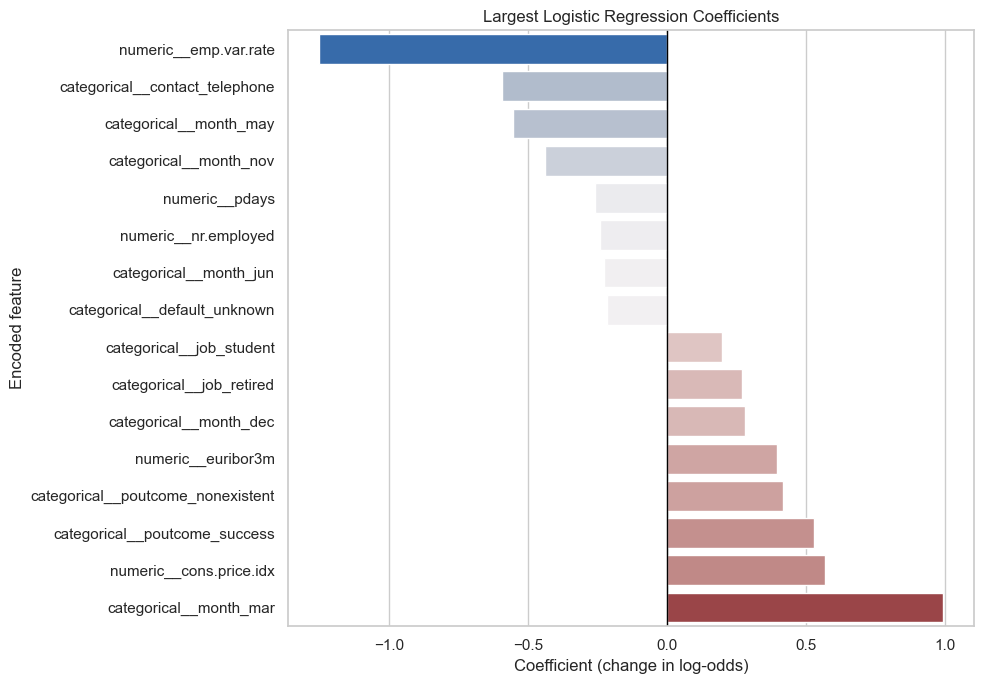

,feature,coefficient
4,numeric__emp.var.rate,-1.2513
36,categorical__contact_telephone,-0.5935
42,categorical__month_may,-0.5533
43,categorical__month_nov,-0.4392
2,numeric__pdays,-0.2588
8,numeric__nr.employed,-0.2398
40,categorical__month_jun,-0.2253
30,categorical__default_unknown,-0.2159
16,categorical__job_student,0.1975
13,categorical__job_retired,0.2699


In [16]:
feature_names = tuned_logistic.named_steps["preprocessor"].get_feature_names_out()
coefficients = tuned_logistic.named_steps["model"].coef_[0]
coefficient_table = pd.DataFrame({"feature": feature_names, "coefficient": coefficients})

largest_coefficients = pd.concat(
    [
        coefficient_table.nsmallest(8, "coefficient"),
        coefficient_table.nlargest(8, "coefficient"),
    ]
).sort_values("coefficient")

plt.figure(figsize=(10, 7))
sns.barplot(data=largest_coefficients, x="coefficient", y="feature", hue="coefficient", palette="vlag", legend=False)
plt.axvline(0, color="black", linewidth=1)
plt.title("Largest Logistic Regression Coefficients")
plt.xlabel("Coefficient (change in log-odds)")
plt.ylabel("Encoded feature")
plt.tight_layout()
plt.show()

largest_coefficients.round(4)

Positive coefficients increase predicted subscription log-odds relative to the omitted reference category, while negative coefficients reduce them. The largest positive signals include March contacts, a successful previous campaign, and retired or student clients. Telephone contact and May contacts are negative signals. Numeric coefficients refer to a one-standard-deviation increase because numeric features were standardized. These are predictive associations, not causal effects.

### Confusion matrices for the two operating choices

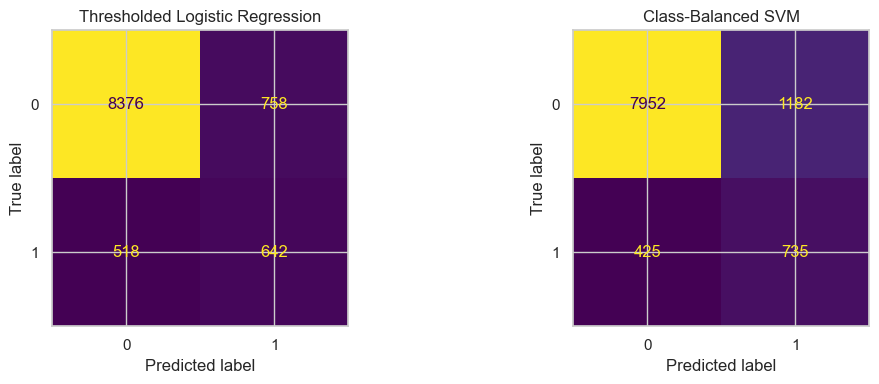

In [17]:
balanced_svm = tuned_pipelines["Support Vector Machine"]
svm_predictions = balanced_svm.predict(X_test)

fig, axes = plt.subplots(1, 2, figsize=(11, 4))
ConfusionMatrixDisplay.from_predictions(y_test, threshold_predictions, ax=axes[0], colorbar=False)
axes[0].set_title("Thresholded Logistic Regression")
ConfusionMatrixDisplay.from_predictions(y_test, svm_predictions, ax=axes[1], colorbar=False)
axes[1].set_title("Class-Balanced SVM")
plt.tight_layout()
plt.show()

## Findings and Actionable Recommendations

1. **Use Logistic Regression as the primary ranking model.** It provides the strongest test ROC-AUC (about 0.802), stable cross-validation performance, fast training, and coefficients that stakeholders can inspect.
2. **Do not deploy the default 0.50 threshold.** It produces high accuracy but identifies only about one-fifth of subscribers. Begin with a threshold near 0.216, then adjust it to the number of calls the team can place.
3. **Choose between two operating profiles.** The thresholded Logistic Regression creates a smaller, higher-precision contact list. The class-balanced SVM reaches more subscribers but requires more calls and produces more false positives.
4. **Prioritize clients with prior successful campaign outcomes.** This segment has the strongest observed conversion rate. Student and retired segments also show elevated rates, but business and fairness review should precede any demographic targeting.
5. **Use seasonal results cautiously.** March, September, October, and December show high observed rates but relatively small sample sizes. Test timing changes prospectively rather than assuming month causes conversion.
6. **Keep `duration` out of pre-call targeting.** It can be used only for retrospective analysis or a separate post-call model.

## Next Steps

- Translate the selected probability threshold into a weekly call-capacity rule.
- Add contact cost and expected deposit value so model selection optimizes expected profit rather than a generic classification metric.
- Validate performance on a later campaign to detect temporal drift.
- Monitor recall, precision, conversion rate, contact volume, and subgroup performance after deployment.
- Consider probability calibration before treating model scores as literal subscription probabilities.

## Conclusion

The bank can improve campaign efficiency by ranking clients before outreach and selecting only the highest-scoring group. Logistic Regression is the recommended starting point because it balances discrimination, speed, and interpretability. The final operating threshold should be chosen with call-center capacity and the relative costs of false positives and false negatives explicitly documented.